# Week 5 · Checking input

Data enters a system through a door: a form, a file, a message. This week you build the check at that door, so bad data is refused with a clear reason before it can cause harm.

| | |
|---|---|
| **This week's question** | What should a system do when the input is wrong? |
| **Python you will learn** | string methods (`strip`, `lower`), `int()`, `try`/`except ValueError`, a list of error messages, returning two values |
| **Principle 5** | **Never trust input.** Check at the door, explain problems in plain words, change nothing when input is bad. |
| **Part you build** | `clean_offer(raw)`: it returns `(offer, errors)` for every offer that arrives |

*Campus Food Rescue is fictional. All organisations, people and numbers are invented.*

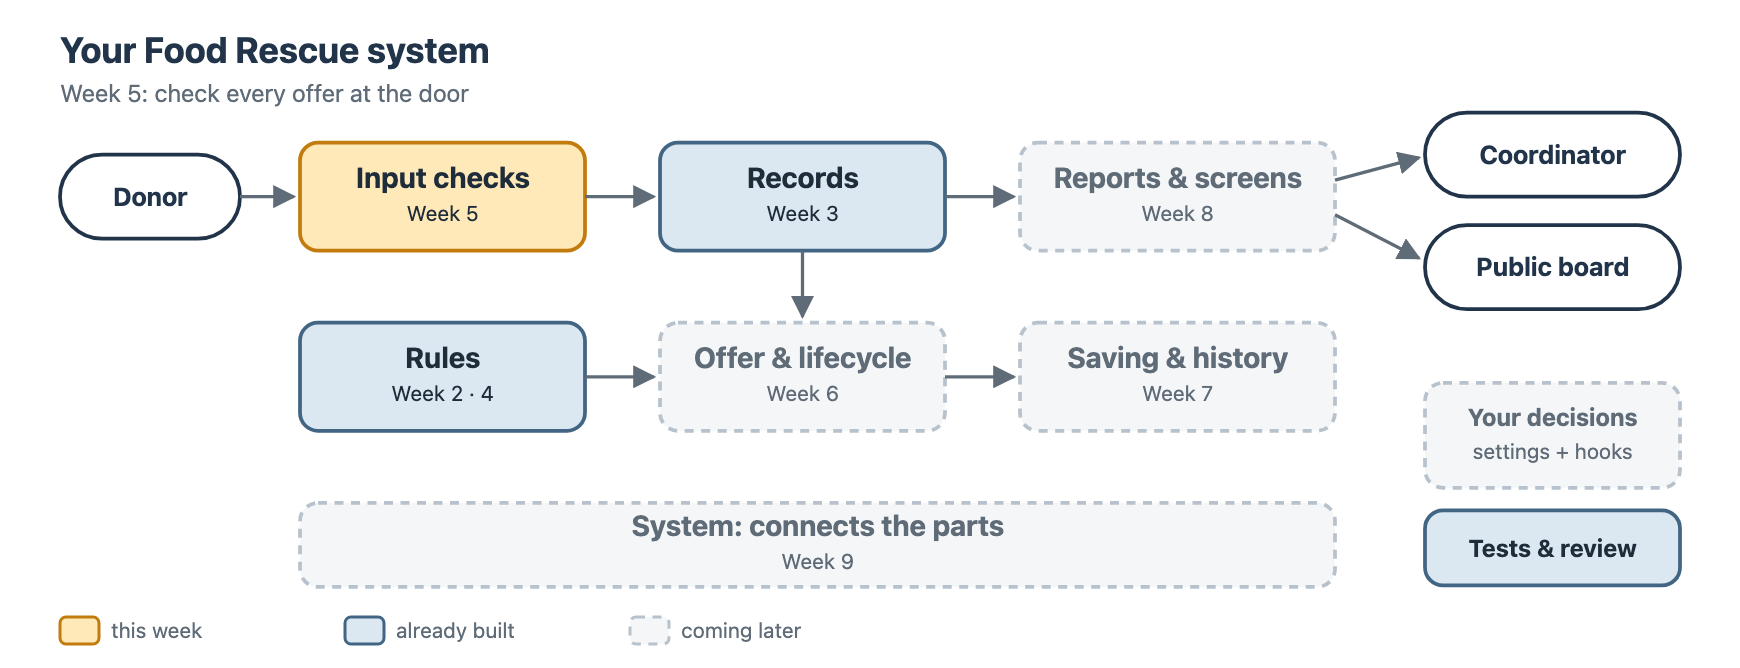

## Before you start

1. **File → Save a copy in Drive**, then work in your copy.
2. Run the setup cell. Run it again after a runtime restart.
3. ⭐ = core for everyone, ⭐⭐ = optional stretch.

In [ ]:
# @title ▶ Run this cell first (setup) — it prepares the Food Rescue system
# It unpacks the course system that is stored inside this notebook.
# No internet, no installation. Run it again after Colab restarts.
import base64, hashlib, importlib, io, os, sys, zipfile
_KIT_VERSION = "2026.11.1"
_KIT_SHA = "01f7d8b96143a6503649613b251e4fa2c46545a5d2a3e781617d8ad990f5189c"
_KIT_ZIP = "..."

def _prepare_kit():
    data = base64.b64decode(_KIT_ZIP)
    if hashlib.sha256(data).hexdigest() != _KIT_SHA:
        raise RuntimeError("This notebook's course files are damaged. Download a fresh copy.")
    marker = os.path.join("food_rescue_kit", ".kit_version")
    current = open(marker).read().strip() if os.path.exists(marker) else ""
    keep = ("food_rescue_kit/my_settings.py", "food_rescue_kit/my_rules.py")
    with zipfile.ZipFile(io.BytesIO(data)) as archive:
        for name in archive.namelist():
            if current == _KIT_VERSION and os.path.exists(name):
                continue                      # already up to date
            if name in keep and os.path.exists(name):
                continue                      # never overwrite your own files
            os.makedirs(os.path.dirname(name), exist_ok=True)
            with open(name, "wb") as target:
                target.write(archive.read(name))
    with open(marker, "w") as file:
        file.write(_KIT_VERSION)
    folder = os.path.abspath("food_rescue_kit")
    if folder not in sys.path:
        sys.path.insert(0, folder)
    for module in [m for m in sys.modules if m == "rescue" or m.startswith("rescue.")]:
        del sys.modules[module]             # load the fresh copy

_prepare_kit()
import rescue as fr
print("✅ Food Rescue system ready (version " + fr.KIT_VERSION + "). You can continue.")


## Class warm-up · Research 3 exchange (10 min)

In groups of three, share the input check you researched.

1. Which form or system did you study? What input does it ask people to type?
2. Which check did you find? What message does a person see when the input is wrong? Is the message in plain words?
3. Name one input it **accepts but should refuse**, or **refuses but should accept**. Who is affected?

📝 **One idea from a classmate that I want to remember:**

## Session 1 · Learn: checking input at the door (30 min)

### The idea: data quality at the boundary

At the airport, staff check your passport and ticket **before** you board, not after the plane takes off. An information system works the same way. Every value comes in through a **door**: a form, a file or a message. The door is the cheapest place to stop bad data. Once bad data is inside, it spreads into totals, reports and decisions, and it is much harder to find.

People are not careless on purpose. They type `many` instead of a number, add extra spaces, or leave a field blank. A good system expects this. It checks every value, tells the person exactly what to fix, and keeps nothing until the input is right.

### 1 · Every value from a file is text

Donors send offers as rows in a CSV file (a simple table saved as text). The kit reads the file for you. Each row becomes a dictionary.

In [ ]:
rows = fr.validation.read_offers_csv("food_rescue_kit/data/offers.csv")
print(len(rows), "rows")
print(rows[0])
print(type(rows[0]["portions"]))

Look at `'portions': '30'`. The quotes show that `'30'` is **text**, not a number. A CSV file is only characters. The file cannot say "this one is a number". A person typed `30`, and another person could type `many`. So the program must check and convert every value itself.

🤔 Run the next cell. Find the **five** rows that the system refused at the door in Week 1. What is wrong with each one?

In [ ]:
for row in rows:
    print(row["donor"], "|", row["food"], "|", row["category"], "|",
          row["portions"], "portions |", row["hours_left"], "hours left")

📝 **Rows that look wrong, and why:**

1.
2.
3.
4.
5.

Sometimes a key is missing completely, for example when a web form forgets a field. `row["donor"]` would then stop with a `KeyError`. `row.get("donor", "")` is safer: it gives the value, or `""` when the key is missing. You will use it in P3 and in your part.

```python
form = {"food": "Mango slices", "portions": "10"}   # no "donor" key
form.get("donor", "")      # gives "" instead of a KeyError
```

### 2 · Tidy text: `strip()` and `lower()`

A **method** is a function that belongs to a value. You write it after a dot. `strip()` removes spaces at both ends. `lower()` changes every letter to lowercase. Both give you a **new** text; the original is not changed.

🤔 **Predict** each line, then run.

In [ ]:
typed = "  Dara "                 # a name typed into a login form
print(typed == "Dara")
print(typed.strip() == "Dara")
print(typed.strip().lower())
print(len(typed), len(typed.strip()))

CATEGORIES = ["bread", "rice meals", "fruit", "vegetables", "snacks"]
print(" Bread " in CATEGORIES)
print(" Bread ".strip().lower() in CATEGORIES)

**Predictions:** …  **Results:** …

Without tidying, `" Bread "` and `"bread"` are different text, and the system would think they are two different categories. With tidying, both become `"bread"`, and `in` finds it in the list.

One more text method you will meet this week: `", ".join(words)` joins a list of texts into one text, with `, ` between them. For example, `", ".join(["bread", "fruit"])` gives `"bread, fruit"`.

### 3 · `int()` turns text into a whole number, or fails

You met `int()` in Week 1. It also ignores spaces at both ends. But when the text is not a whole number, it stops the program with a `ValueError`.

In [ ]:
print(int("30") + 4)
print(int(" 12 "))
print(int("-3"))
# print(int("many"))     # remove the # to see the error, then put it back

🤔 Which of these work with `int()`: `"7"`, `"seven"`, `"7.5"`, `""`? Try them in the cell above.

**My answer:** …

Notice `int("-3")` works. `-3` **is** a whole number, but it is not a sensible number of portions. Converting is one check. The **range** (is it between the limits?) is a second check.

### 4 · `try` / `except ValueError`: plan for the problem

When you **expect** a problem, you can plan for it. Python runs the lines under `try`. If one of them raises a `ValueError`, Python jumps to `except` instead of stopping.

In [ ]:
quantity_text = "two"           # typed into a phone shop's order form
try:
    quantity = int(quantity_text)
    print("Order for", quantity, "phones")
except ValueError:
    print("Please type the quantity as a number, for example 2.")

🤔 Change `"two"` to `"2"` and predict the output before you run.

**Prediction:** …  **Result:** …

Two good habits:

- Keep `try` **small**: only the line that can fail (the conversion).
- Catch **only** `ValueError`, the problem you expect. Other mistakes in your code should still show, so that you can fix them.

### 5 · A list of error messages

Imagine a form that shows only the first problem. The donor fixes it, sends again, and gets the next problem. That wastes time. A better door checks **everything**, collects every problem in a list, and explains each one in plain words.

In [ ]:
name = "  "
age_text = "seventeen"
errors = []

if name.strip() == "":
    errors.append("name is required.")
try:
    age = int(age_text)
except ValueError:
    errors.append("age must be a whole number, for example 19.")

print(errors)
print(len(errors), "problem(s)")

Compare Python's own message `invalid literal for int() with base 10: 'many'` with `portions must be a whole number, for example 12.` A donor reads these messages, not a programmer. Say **what** is wrong and **how** to fix it.

### 6 · Return two values, then unpack them

A function can send back two values at once: `return age, errors`. The caller **unpacks** them into two names: `age, errors = check_age("17")`. The first value goes into the first name, the second into the second.

In [ ]:
def check_age(age_text):
    """Return (age, errors). age is None when there is a problem."""
    try:
        age = int(age_text)
    except ValueError:
        return None, ["age must be a whole number, for example 19."]
    if age < 16:
        return None, ["volunteers must be 16 or older."]
    return age, []

age, errors = check_age("17")
print(age, errors)

🤔 **Predict** what `check_age("abc")` and `check_age("12")` return. Then add two lines to the cell and check.

**Prediction:** …  **Result:** …

This is the shape of your part this week: a good value with an empty list, **or** `None` with a list of problems. Never both. `None` means "no offer was created", so nothing in the system changes. That is all three parts of Principle 5: check at the door, explain in plain words, change nothing.

## Session 2 · Practise and judge (60 min)

### ⭐ P1 · Predict the tidy text

Write your prediction for each line, then run.

In [ ]:
print(" Rice Meals ".strip())
print(" Rice Meals ".lower())
print(" Rice Meals ".strip().lower() == "rice meals")
print("   ".strip() == "")
print(len("  bread  ".strip()))

**Predictions:** …  **Results:** …

<details><summary>Show a possible answer</summary>

`Rice Meals`, ` rice meals ` (the spaces stay, because `lower()` only changes letters), `True`, `True`, `5`. The fourth line is how you test for a blank field: a value with only spaces is still blank.

</details>

### ⭐ P2 · Repair the crash

A teacher's program reads exam marks typed by assistants. `int("absent")` crashes it. Write `read_mark(text)` so that it returns the mark as an `int`, or `None` when the text is not a whole number. Put only the conversion inside `try`.

In [ ]:
def read_mark(text):
    """Return the mark as an int, or None when text is not a whole number."""
    # TODO: try int(text); in except ValueError, return None
    return None

print(read_mark("75"), read_mark(" 80 "), read_mark("absent"), read_mark(""))

Expected: `75 80 None None`.

<details><summary>Show a possible answer</summary>

```python
def read_mark(text):
    try:
        return int(text)
    except ValueError:
        return None
```

`None` means "no value". The caller can test `if mark is None:` and decide what to say. The program does not stop, and it does not pretend that `"absent"` is a number.

</details>

### ⭐ P3 · Collect every missing field

A volunteer sign-up form must have a name, a phone number and a faculty. Loop over `REQUIRED` and add one message for **each** blank field. Remember that a value with only spaces is blank.

In [ ]:
REQUIRED = ["name", "phone", "faculty"]
form = {"name": "Sokha", "phone": "   ", "faculty": ""}

errors = []
for field in REQUIRED:
    value = form.get(field, "")
    # TODO: if value is blank after strip(), add field + " is required." to errors

print(errors)

Expected: `['phone is required.', 'faculty is required.']`. Now delete the `"faculty"` key from `form` and run again. Why does the code still work?

**My answer:** …

<details><summary>Show a possible answer</summary>

```python
for field in REQUIRED:
    value = form.get(field, "")
    if value.strip() == "":
        errors.append(field + " is required.")
```

Without the key, `form.get("faculty", "")` gives `""`, so the field is reported as required instead of crashing with a `KeyError`. Your `clean_offer` uses the same loop for `REQUIRED_FIELDS`.

</details>

### ⭐ P4 · Two values back

A shop's stock form needs a quantity between 1 and 500. Write `clean_quantity(text)` that returns `(quantity, errors)`:

- not a whole number → `(None, ["quantity must be a whole number."])`
- outside 1 to 500 → `(None, ["quantity must be between 1 and 500."])`
- otherwise → `(quantity, [])`

In [ ]:
MIN_QUANTITY = 1
MAX_QUANTITY = 500

def clean_quantity(text):
    # TODO: convert with try/except, then check the range
    return None, ["not done yet"]

quantity, errors = clean_quantity("40")
print(quantity, errors)
quantity, errors = clean_quantity("lots")
print(quantity, errors)
quantity, errors = clean_quantity("900")
print(quantity, errors)

<details><summary>Show a possible answer</summary>

```python
def clean_quantity(text):
    try:
        quantity = int(text)
    except ValueError:
        return None, ["quantity must be a whole number."]
    if quantity < MIN_QUANTITY or quantity > MAX_QUANTITY:
        return None, [f"quantity must be between {MIN_QUANTITY} and {MAX_QUANTITY}."]
    return quantity, []
```

Expected: `40 []`, then `None ['quantity must be a whole number.']`, then `None ['quantity must be between 1 and 500.']`. Test the boundaries too: `"1"` and `"500"` are accepted, `"0"` and `"501"` are not.

</details>

### ⭐⭐ S1 · Surprising numbers

`int()` accepts more than you might expect. Predict, then run. For each value, decide: **should the food rescue system accept it as a number of portions?** There is no single right answer; give a reason.

In [ ]:
for text in ["១២", "+5", "1_000", "12.0", "1,200", "0"]:
    try:
        print(repr(text), "→", int(text))     # repr() shows the quotes
    except ValueError:
        print(repr(text), "→ ValueError")

**My decisions and reasons:** …

### ⚖️ Good or risky?

You asked an AI assistant: *"Write Python that reads offers from the CSV file and saves them."* It gave you **Version A**. When A crashed on the cupcakes row, you said *"it crashes"*, and it gave you **Version B**: *"Fixed! It will never crash now."*

**Version A**

```python
saved_offers = []

def add_offer(raw):
    offer = {
        "donor": raw["donor"],
        "food": raw["food"],
        "category": raw["category"],
        "portions": int(raw["portions"]),
        "hours_left": int(raw["hours_left"]),
    }
    saved_offers.append(offer)
    return "OK"
```

**Version B**

```python
saved_offers = []

def add_offer(raw):
    offer = {"donor": raw["donor"], "food": raw["food"]}
    saved_offers.append(offer)               # save straight away
    try:
        offer["portions"] = int(raw["portions"])
    except:
        offer["portions"] = 0                # never crash
    try:
        offer["hours_left"] = int(raw["hours_left"])
    except:
        offer["hours_left"] = 0
    if raw["category"] not in CATEGORIES:
        return "error"
    offer["category"] = raw["category"]
    return "OK"
```

Run Version B on the sample file and read what it saved.

In [ ]:
CATEGORIES = ["bread", "rice meals", "fruit", "vegetables", "snacks"]
saved_offers = []

def add_offer(raw):
    offer = {"donor": raw["donor"], "food": raw["food"]}
    saved_offers.append(offer)               # save straight away
    try:
        offer["portions"] = int(raw["portions"])
    except:
        offer["portions"] = 0                # never crash
    try:
        offer["hours_left"] = int(raw["hours_left"])
    except:
        offer["hours_left"] = 0
    if raw["category"] not in CATEGORIES:
        return "error"
    offer["category"] = raw["category"]
    return "OK"

for row in rows:
    print(add_offer(row), "·", row["food"])
print(len(saved_offers), "offers saved:")
for offer in saved_offers:
    print(offer)

Use **Principle 5 (never trust input)**. Is B better than A? Find **at least three** problems in B. For each one, name the offer or person who is harmed.

📝 **Problems I found:**

1.
2.
3.

**Is B better than A? Why?**

<details><summary>Instructor's view</summary>

**Version A** fails loudly. On the cupcakes row, `int("many")` stops the whole program. The Student Club Bake Sale gets no answer, and the three rows after it (corn, rice, mango) are never read. A also accepts anything that converts: it saves the noodle soup in a category that does not exist, and if the 1200-portion rice or the mango row with no donor came before the cupcakes, it would save those too.

**Version B** never crashes, but it is **silently wrong**:

1. **Bad values become 0.** The Student Club's "many" cupcakes are saved as 0 portions. The club thinks its offer was accepted, and no volunteer goes to collect real food.
2. **Half an offer is saved.** The noodle soup is added to `saved_offers` **before** the category check. B returns `"error"`, but the record without a category stays. Every later report must deal with it.
3. **The message says nothing.** `"error"` does not tell Riverside Restaurant what to fix.
4. **Bare `except:`** hides every problem, even a typo in the code, so bugs become invisible.
5. **Still no limits.** 1200 portions and 0 hours left are accepted, and the mango offer has no donor to call.

B is **more** dangerous than A. A crash is annoying, but everyone notices it. A quiet wrong answer goes into the totals, and people act on it. A safe door does four things: tidy the text, check **everything** and collect every problem, create the offer **only** when the list is empty, and explain each problem in plain words. That is your part in Session 3.

</details>

## Session 3 · Build your part: the check at the door (60–80 min)

Every offer enters the system through `add_offer`. Before it creates a record, the system calls `clean_offer(raw)`. Three groups of people depend on it:

- the **donor** reads the messages and fixes the offer;
- the **coordinator** gets clean records with real numbers;
- the **reports** show honest totals (Week 8).

The promise (the contract) of `clean_offer(raw)`:

| Input | Return |
|---|---|
| a good row | `(offer, [])`: text stripped, category lowercase, `portions` and `hours_left` as `int` |
| a bad row | `(None, [every problem in plain words])` |

### Your limits (constants)

These are the coordinator's decisions. Keep the defaults for now; you will choose your own at the end.

In [ ]:
MIN_PORTIONS = 1
MAX_PORTIONS = 200
REJECT_IF_HOURS_LEFT_BELOW = 1
CATEGORIES = ["bread", "rice meals", "fruit", "vegetables", "snacks"]
REQUIRED_FIELDS = ["donor", "food", "category", "portions", "hours_left"]

### Step 1 · A helper that converts a whole number

This is the same pattern as `read_mark` in P2.

In [ ]:
def to_whole_number(text):
    """Return text as an int, or None when it is not a whole number."""
    # TODO 1: try int(text); in except ValueError, return None
    return None

print(to_whole_number("30"), to_whole_number(" 5 "), to_whole_number("many"), to_whole_number(""))

Expected: `30 5 None None`.

### Step 2 · `clean_offer`

Most of the function is written for you. Fill in the three `TODO`s. Read the comments: they tell you exactly what each part must do.

In [ ]:
def clean_offer(raw):
    """Check one raw row at the door.

    Return (offer, []) for a good row, or (None, errors) for a bad row.
    """
    errors = []

    # TODO 2: tidy the text. Add .strip() to all four lines, and also .lower() for category.
    donor = raw.get("donor", "")
    contact = raw.get("contact", "")
    food = raw.get("food", "")
    category = raw.get("category", "")

    # Required fields must not be blank (done for you, like P3).
    for field in REQUIRED_FIELDS:
        if raw.get(field, "").strip() == "":
            errors.append(field + " is required.")

    # Numbers: your helper turns the text into an int, or None.
    portions = to_whole_number(raw.get("portions", ""))
    hours_left = to_whole_number(raw.get("hours_left", ""))

    # TODO 3: range checks. Add an elif under each if:
    #   portions below MIN_PORTIONS or above MAX_PORTIONS
    #       -> "portions must be between ... and ..."
    #   hours_left below REJECT_IF_HOURS_LEFT_BELOW
    #       -> "too late to collect: ... hours left, the minimum is ..."
    if portions is None:
        errors.append("portions must be a whole number, for example 12.")
    if hours_left is None:
        errors.append("hours_left must be a whole number of hours.")

    # TODO 4: if category is not in CATEGORIES, add
    #   "category must be one of: bread, rice meals, ..."  (hint: ", ".join(CATEGORIES))

    if errors:
        return None, errors        # change nothing: no offer at all
    offer = {"donor": donor, "contact": contact, "food": food, "category": category,
             "portions": portions, "hours_left": hours_left}
    return offer, []

Try it on a messy but good row, and on a row with three problems.

In [ ]:
messy = {"donor": " Lotus Cafe ", "contact": "lotus@example.org", "food": "Steamed buns",
         "category": " Snacks ", "portions": " 15 ", "hours_left": "3"}
print(clean_offer(messy))

bad = {"donor": "Lotus Cafe", "food": "Soup", "category": "soup",
       "portions": "-3", "hours_left": "soon"}
print(clean_offer(bad))

When you are finished, the first line shows a dictionary with `'category': 'snacks'` and `'portions': 15` (no quotes: a number), followed by `[]`. The second line shows `None` and **three** messages.

### Check it

The checker tries a good row with extra spaces, then one bad value at a time. It uses **your** limits, so it still works after you change them.

In [ ]:
MY_SETTINGS = {
    "MIN_PORTIONS": MIN_PORTIONS,
    "MAX_PORTIONS": MAX_PORTIONS,
    "REJECT_IF_HOURS_LEFT_BELOW": REJECT_IF_HOURS_LEFT_BELOW,
    "CATEGORIES": CATEGORIES,
    "REQUIRED_FIELDS": REQUIRED_FIELDS,
}
fr.check("clean_offer", clean_offer, MY_SETTINGS)

🤔 Imagine a `clean_offer` that refuses every row: `return None, ["no"]`. How many of the 7 cases would pass? Which case catches it, and why is that case important?

**My answer:** …

### Plug it in

Now your door guards the real system. Look at step 1 of the day: every 🚫 line is a row that **your** `clean_offer` refused, with **your** message.

In [ ]:
my_system = fr.System(MY_SETTINGS, hooks={"clean_offer": clean_offer})
my_system.run_day()

A refusal must change nothing. Test it: add a bad offer and compare the records before and after. Then add the messy but good offer from above.

In [ ]:
before = my_system.records()
offer_id, errors = my_system.add_offer({"donor": "Hotel Kitchen", "contact": "hotel@example.org",
                                        "food": "Steamed rice", "category": "Rice Meals",
                                        "portions": "-3", "hours_left": "8"})
print("Bad offer →", offer_id, errors)
print("Records unchanged:", my_system.records() == before)

offer_id, errors = my_system.add_offer(messy)
print("Messy but good offer →", offer_id, errors)
for record in my_system.records():
    print("  ", record["id"], "·", record["food"], "·", record["category"], "·", record["portions"], "portions")

### 🧭 Your decision · what does the door accept?

The coordinator asks you to set the door's limits. Every limit protects someone and refuses someone.

- **`MIN_PORTIONS` / `MAX_PORTIONS`:** is a 1-portion offer worth a volunteer's trip? Can any partner take 200 portions?
- **`REJECT_IF_HOURS_LEFT_BELOW`:** with 1 hour left, can a volunteer still get there?
- **`REQUIRED_FIELDS`:** which fields must a donor fill in? For example, **should `contact` be required?** With a contact, the team can arrange the pickup and call when there is a problem. But the system then holds more personal data that it must protect (Week 8), and some small donors may stop offering.

1. Change the constants in **Your limits** above. You may keep a default if you can explain why.
2. Run again from that cell down to here. The check still passes, because it uses your limits.
3. Run the cell below to see what your door does with the sample day.

In [ ]:
for row in fr.validation.read_offers_csv("food_rescue_kit/data/offers.csv"):
    offer, errors = clean_offer(row)
    if errors:
        print("🚫", row["food"], "→", " ".join(errors))
    else:
        print("✅", offer["food"], "·", offer["portions"], "portions ·", offer["hours_left"], "hours left")

📝 **Decision log · Week 5**

| | |
|---|---|
| **My choice** | portions from … to …; refuse below … hours left; required: … |
| **An alternative I considered** | |
| **Why I chose it** | |
| **Who is affected (the tradeoff)** | |

### ⭐⭐ Stretch · one message for the donor

A list is good for the program, but a donor wants one friendly message. Write `message_for_donor(errors)` that returns text such as `"Sorry, we could not accept your offer: 1) portions must be ... 2) category must be ..."`, or `"Thank you, your offer was accepted."` when the list is empty.

In [ ]:
def message_for_donor(errors):
    return "?"

offer, errors = clean_offer(bad)
print(message_for_donor(errors))
print(message_for_donor([]))

## Finish

- [ ] I shared my Research 3 finding in the warm-up.
- [ ] My `read_mark` and `clean_quantity` refuse bad text without crashing.
- [ ] I found at least three problems in Version B, and I can explain why "silently wrong" is worse than a crash.
- [ ] `clean_offer` passes every check, and `run_day()` shows my door refusing rows with 🚫.
- [ ] My decision log explains my limits and required fields.

### Research 4 · How systems keep data and history (5%)

Choose a real system that keeps records over time: a bank statement, your school records, a phone's call log, a library account.

1. **What is kept?** List the main pieces of data in one record.
2. **Which IDs are used?** For example an account number or a student ID. Why does each record need one?
3. **What happens when something is corrected?** Is the old value kept, replaced, or shown as a correction? How can you tell?
4. **Who needs the history**, and why?

Describe the kinds of data; do not copy your own real numbers or personal details. Use at least one source and name it. If you use an AI assistant, show one place where you checked or corrected it. Bring your example to the **Week 6 class warm-up**. Submit by email to submit.progmis@gmail.com; the deadline and file name will be announced in class.

**Next week:** a clean offer still has a journey: new, approved, picked up, delivered. You will make sure it can only move the right way.